# 03 - LSTM : entraînement, évaluation et prévisions (Agent 1)

Ce notebook **ne réentraîne rien** et **ne touche pas au jeu de test** : il lit les fichiers déjà produits par le pipeline
(`outputs/`, `models/`) et les présente. Exécute-le avec *Restart & Run All*.

هذا الدفتر لا يعيد التدريب ولا يلمس مجموعة الاختبار، بل يعرض النتائج المحفوظة فقط.

Ordre des commandes qui produisent ces fichiers : voir `README.md`.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
OUT, MODELS = ROOT / "outputs", ROOT / "models"
pd.options.display.float_format = "{:,.2f}".format
print("Project root:", ROOT)

def load_json(name):
    p = OUT / name
    if not p.exists():
        print(f"[absent] {p.name} : lance l'étape correspondante (voir README).")
        return None
    return json.loads(p.read_text(encoding="utf-8"))

Project root: C:\Users\le\Desktop\dynamic-pricing-ecommerce


## 1. Découpage chronologique et données

In [2]:
info = load_json("split_info.json")
if info:
    print("Produits :", len(info["products"]))
    print("Fenêtre :", info["window_size"], "semaines -> horizon :", info["horizon"], "semaines")
    print("Dates de coupure :", info["split_dates"])
    print("Échantillons :", info["n_samples"])
    print("Variables (%d) :" % len(info["feature_cols"]), info["feature_cols"])

Produits : 32
Fenêtre : 12 semaines -> horizon : 4 semaines
Dates de coupure : {'train_end': '2016-08-08', 'val_end': '2017-02-06', 'test_end': '2017-08-07', 'first_week': '2013-02-25'}
Échantillons : {'train': 4785, 'val': 736, 'test': 736}
Variables (18) : ['log_sales', 'lag_1', 'lag_2', 'lag_4', 'roll_mean_4', 'roll_std_4', 'roll_mean_8', 'roll_std_8', 'log_promo', 'promo_available', 'open_stores', 'woy_sin', 'woy_cos', 'month_sin', 'month_cos', 'n_holidays', 'n_events', 'is_christmas_week']


## 2. Entraînement (modèle principal)
La perte d'entraînement et de validation doivent rester proches (pas de sur-apprentissage marqué). L'arrêt anticipé restaure les meilleurs poids.

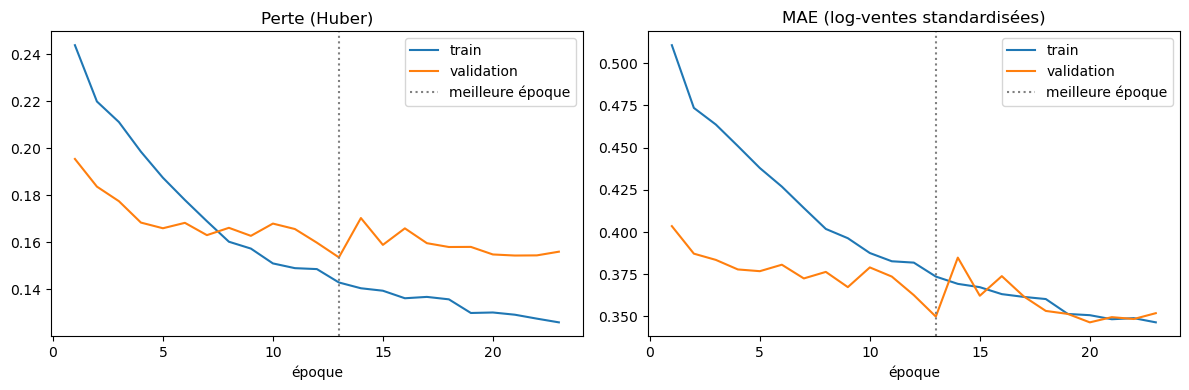

{'epochs_run': 23, 'best_epoch': 13, 'best_val_loss': 0.15365701913833618, 'train_loss_at_best': 0.14298710227012634, 'best_val_mae_scaled': 0.34992101788520813, 'n_train_samples': 4785, 'n_val_samples': 736, 'n_parameters': 10756, 'uses_product_embedding': True, 'uses_seasonal_input': True, 'target_mode': 'delta', 'model_file': 'C:\\Users\\le\\Desktop\\dynamic-pricing-ecommerce\\models\\lstm_demand_model.keras', 'seed': 42}


In [3]:
hist_path = OUT / "training_history.csv"
if hist_path.exists():
    h = pd.read_csv(hist_path)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, (c, t) in zip(ax, [("loss", "Perte (Huber)"), ("mae", "MAE (log-ventes standardisées)")]):
        a.plot(h.index + 1, h[c], label="train"); a.plot(h.index + 1, h["val_" + c], label="validation")
        a.axvline(h["val_loss"].idxmin() + 1, color="gray", linestyle=":", label="meilleure époque")
        a.set_title(t); a.set_xlabel("époque"); a.legend()
    plt.tight_layout(); plt.show()
else:
    print("[absent] training_history.csv")
print(load_json("training_summary.json"))

## 3. Les 5 réseaux de l'ensemble (graines 42 à 46)

In [4]:
rows = []
for p in sorted(OUT.glob("training_summary_ens_s*.json")):
    s = json.loads(p.read_text(encoding="utf-8"))
    rows.append({"graine": s["seed"], "meilleure_époque": s["best_epoch"], "val_loss": s["best_val_loss"],
                 "paramètres": s["n_parameters"]})
members = OUT / "ensemble_members_val.csv"
if rows:
    print(pd.DataFrame(rows).to_string(index=False))
if members.exists():
    m = pd.read_csv(members)
    print("\nWAPE de chaque réseau sur la validation (%) :")
    print(m[["seed", "WAPE", "MAE", "RMSE", "bias"]].to_string(index=False))
    print(f"min {m.WAPE.min():.2f} / moyenne {m.WAPE.mean():.2f} / max {m.WAPE.max():.2f}  -> variabilité entre graines")

 graine  meilleure_époque  val_loss  paramètres
     42                13      0.15       10756
     43                11      0.15       10756
     44                28      0.15       10756
     45                21      0.15       10756
     46                12      0.14       10756

WAPE de chaque réseau sur la validation (%) :
 seed  WAPE       MAE      RMSE       bias
   42  9.14 16,519.64 53,696.65 -11,053.21
   43 10.64 19,232.76 58,618.31 -14,717.27
   44  8.08 14,611.30 44,387.36  -8,686.58
   45  9.95 17,989.14 61,778.28 -11,835.78
   46  8.05 14,557.28 44,110.81  -5,742.30
min 8.05 / moyenne 9.17 / max 10.64  -> variabilité entre graines


## 4. Évaluation sur la VALIDATION
Métriques en unités d'origine (ventes hebdomadaires). **WAPE** = somme des erreurs absolues / somme des ventes : c'est la métrique de comparaison principale (MAE et RMSE sont dominées par les gros produits).
`lstm` = moyenne des 5 réseaux ; `diag_blend_seasonal` = diagnostic seulement.

In [5]:
ev = load_json("ensemble_val.json")
if ev:
    cols = ["MAE", "RMSE", "MAPE", "WAPE", "sMAPE", "bias"]
    print(pd.DataFrame(ev["overall"]).T[cols].round(2).to_string())
    n_h = len(next(iter(ev["by_horizon"].values())))
    print("\nWAPE (%) par horizon :")
    print(pd.DataFrame({k: [x["WAPE"] for x in v] for k, v in ev["by_horizon"].items()},
                       index=[f"semaine +{i+1}" for i in range(n_h)]).round(1).to_string())
    print()
    for line in ev.get("verdict", []):
        print(line)

                          MAE      RMSE  MAPE  WAPE  sMAPE       bias
lstm                15,866.02 49,789.01 15.05  8.77  13.54 -10,407.03
lstm_single         16,519.64 53,696.65 15.63  9.14  14.09 -11,053.21
naive               20,647.55 65,499.25 18.78 11.42  15.01  -2,883.26
moving_average      18,074.64 58,768.69 20.05 10.00  15.15  -5,199.81
seasonal_naive      15,340.73 46,367.11 20.67  8.48  19.51  -8,467.73
diag_blend_seasonal 13,236.51 42,479.95 15.54  7.32  14.12  -9,437.38

WAPE (%) par horizon :
            lstm  lstm_single  naive  moving_average  seasonal_naive  diag_blend_seasonal
semaine +1  7.50         7.50   9.50            9.00            8.20                 6.30
semaine +2  8.30         8.70  12.00            9.90            8.30                 6.90
semaine +3  9.90        10.00  13.10           10.40            8.80                 7.90
semaine +4  9.40        10.30  11.00           10.70            8.70                 8.10

Best model by pooled WAPE: diag_ble

## 5. Évaluation FINALE sur le TEST (exécutée une seule fois)
Résultat obtenu une seule fois par `python -m src.forecast.final_evaluation --final`. `hybrid` = 0,5 × ensemble LSTM + 0,5 × saisonnier naïf.

In [6]:
ft = load_json("evaluation_test_final.json")
if ft:
    cols = ["MAE", "RMSE", "MAPE", "WAPE", "sMAPE", "bias"]
    print(pd.DataFrame(ft["overall"]).T[cols].round(2).to_string())
    n_h = len(next(iter(ft["by_horizon"].values())))
    print("\nWAPE (%) par horizon :")
    print(pd.DataFrame({k: [x["WAPE"] for x in v] for k, v in ft["by_horizon"].items()},
                       index=[f"semaine +{i+1}" for i in range(n_h)]).round(1).to_string())
    print("\nWAPE moyen par produit (%) :", {k: round(v, 1) for k, v in ft["macro_wape"].items()})
    print()
    for line in ft.get("verdict", []):
        print(line)

                     MAE      RMSE  MAPE  WAPE  sMAPE       bias
hybrid         16,244.10 54,911.42 12.58  8.63  13.54 -10,635.75
lstm           13,185.32 45,327.87 11.95  7.01  11.73  -3,382.40
lstm_single    13,290.55 44,191.46 12.44  7.06  12.20  -1,963.44
naive          14,970.81 45,210.66 13.14  7.95  12.32    -622.28
moving_average 11,660.76 34,185.94 13.39  6.20  11.50    -522.21
seasonal_naive 23,833.03 74,859.07 17.82 12.66  20.82 -17,889.10

WAPE (%) par horizon :
            hybrid  lstm  lstm_single  naive  moving_average  seasonal_naive
semaine +1    8.10  6.40         6.40   7.70            6.20           12.30
semaine +2    8.60  7.00         6.90   8.60            6.00           12.60
semaine +3    9.30  7.80         7.60   9.20            6.30           12.90
semaine +4    8.60  6.80         7.30   6.30            6.20           12.90

WAPE moyen par produit (%) : {'hybrid': 13.2, 'lstm': 11.9, 'lstm_single': 12.4, 'naive': 12.7, 'moving_average': 11.8, 'seasonal_naive

In [7]:
bp = OUT / "evaluation_test_final_by_product.csv"
if bp.exists():
    t = pd.read_csv(bp).sort_values("mean_weekly_sales", ascending=False)
    show = ["product_id", "mean_weekly_sales", "WAPE_hybrid", "WAPE_lstm", "WAPE_naive", "WAPE_moving_average", "best_model"]
    print(t[show].round(1).to_string(index=False))

                product_id  mean_weekly_sales  WAPE_hybrid  WAPE_lstm  WAPE_naive  WAPE_moving_average     best_model
                 GROCERY I       1,786,464.00         9.80       7.30        8.70                 6.40 moving_average
                 BEVERAGES       1,360,965.40        11.00       7.40        7.40                 6.20 moving_average
                   PRODUCE         902,076.50         5.30       5.50        5.10                 3.70 moving_average
                  CLEANING         481,546.90         9.50       7.90       11.00                 8.80    lstm_single
                     DAIRY         355,827.80         4.90       5.40        6.80                 5.70         hybrid
              BREAD/BAKERY         210,570.50         4.30       4.80        6.50                 4.90         hybrid
                   POULTRY         147,749.60         4.90       6.30        8.10                 6.00         hybrid
                     MEATS         140,151.70         5.

## 6. Prévisions livrées à l'Agent 3 (`demand_forecast.csv`)
Colonnes obligatoires : `product_id`, `week`, `demand_pred` (+ `horizon`). Le contrat complet est dans `CONTRACT.md`.

(128, 4) | semaines : ['2017-08-14', '2017-08-21', '2017-08-28', '2017-09-04']
product_id       week  demand_pred  horizon
AUTOMOTIVE 2017-08-14     2,520.61        1
AUTOMOTIVE 2017-08-21     2,464.96        2
AUTOMOTIVE 2017-08-28     2,718.06        3
AUTOMOTIVE 2017-09-04     2,421.04        4
 BABY CARE 2017-08-14        82.52        1
 BABY CARE 2017-08-21        68.67        2
 BABY CARE 2017-08-28       101.07        3
 BABY CARE 2017-09-04        78.47        4

Validation du contrat : VALIDE


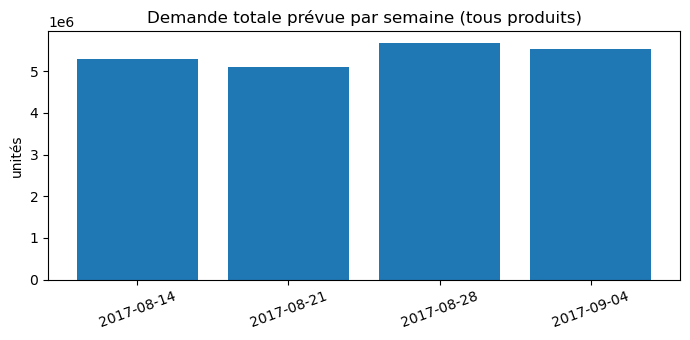

Origine : 2017-08-07 | poids saisonnier : 0.5


In [8]:
fc_path = OUT / "demand_forecast.csv"
if fc_path.exists():
    fc = pd.read_csv(fc_path, dtype={"product_id": str})
    print(fc.shape, "| semaines :", sorted(fc["week"].unique()))
    print(fc.head(8).to_string(index=False))
    try:
        from src.forecast.export_forecast import validate_forecast
        problems = validate_forecast(fc, info["products"] if info else None)
        print("\nValidation du contrat :", "VALIDE" if not problems else problems)
    except Exception as exc:
        print("Validation non exécutée :", exc)
    tot = fc.groupby("week")["demand_pred"].sum()
    plt.figure(figsize=(7, 3.5)); plt.bar(tot.index, tot.values); plt.title("Demande totale prévue par semaine (tous produits)")
    plt.ylabel("unités"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()
    meta = load_json("demand_forecast_info.json")
    print("Origine :", meta and meta["origin_week"], "| poids saisonnier :", meta and meta["seasonal_weight"])
else:
    print("[absent] demand_forecast.csv : lance python -m src.forecast.export_forecast")

## 7. Reproduire les résultats
Commandes (depuis la racine du projet) : voir `README.md`. Ne **jamais** relancer `sequence_generator` sur de nouvelles données sans réentraîner les réseaux : il réécrit `models/feature_scaler.json`.

Limites principales : pas de colonne prix dans les données ; `product_id` = famille de produits ; un seul jeu de test de 26 semaines ; le saisonnier naïf dépend d'une année de référence (2016) atypique. Détails dans `RAPPORT_AGENT1.md`.